# 05 · Segmentación, asociaciones y alerta temprana

**Estado:** plantilla y herramientas de análisis. El repositorio no contiene observaciones de tarjeta: con las plantillas vacías no hay métricas ni perfiles estimados. Una anomalía no equivale a fraude y asociación no implica causalidad.

**Objetivo:** pasar de las cohortes maduras del notebook 02 a perfiles interpretables y, si existe una muestra apta, explorar una alerta posterior a MOB 1. El indicador principal de backtesting es *EVER DPD > 30 a MOB 3*, sujeto al contrato de métricas y a la regla de saldo aprobada.

## 1 · ¿Cuándo se conoce cada dato?

| Uso | Información admisible | Resultado posterior |
|---|---|---|
| Originación | score, tipo, estrategia y ubicación disponibles al aprobar | primer DPD >30 entre MOB 1 y MOB 3 |
| Alerta después de MOB 1 | lo anterior y avances disponibles **hasta MOB 1**, entre cuentas aún en riesgo | primer DPD >30 en MOB 2–3 |
| Análisis descriptivo al cierre de MOB 3 | trayectoria completa hasta MOB 3 | EVER >30, número y saldo |

La etiqueta de la alerta no es la misma que el EVER completo: se excluyen los casos que ya tuvieron el evento en MOB 1. Se deben registrar fecha efectiva y fecha de disponibilidad; fecha de evento por sí sola no prueba disponibilidad. Una variable del resultado no entra al ajuste de perfiles predictivos.

Referencias metodológicas: [documentación AFM mixto de Prince](https://maxhalford.github.io/prince/mfa/) y [prevención de fuga, scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
if not (BASE/'plantilla_panel_mensual.csv').exists():
    BASE = next(p for p in [BASE, *BASE.parents] if (p/'03-financial-risk').is_dir()) / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'font.size': 10, 'axes.titleweight': 'bold'})
print('Carpeta del laboratorio:', BASE)


Carpeta del laboratorio: /Users/admin/Portafolio-vintage-review/03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab


## 2 · Mapa del flujo de evidencia

Diagrama conceptual; no contiene resultados ni tasas de una cartera. El reparto en entrenamiento y evaluación se hace por cohorte y fecha de disponibilidad del resultado.

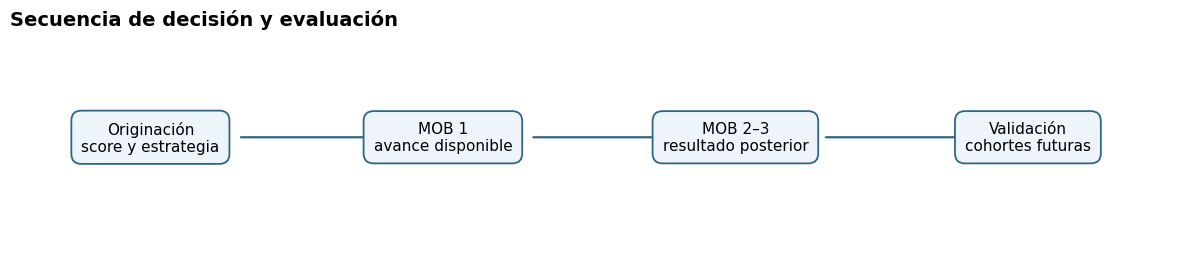

In [2]:
fig, ax = plt.subplots(figsize=(12, 2.7)); ax.axis('off')
labels = ['Originación\nscore y estrategia', 'MOB 1\navance disponible', 'MOB 2–3\nresultado posterior', 'Validación\ncohortes futuras']
for i, label in enumerate(labels):
    x=.12+i*.25
    ax.text(x,.55,label,transform=ax.transAxes,ha='center',va='center',fontsize=11,
            bbox=dict(boxstyle='round,pad=.65',fc='#edf5fb',ec='#306587',lw=1.3))
    if i<3: ax.annotate('',xy=(x+.20,.55),xytext=(x+.075,.55),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#306587',lw=1.6))
ax.set_title('Secuencia de decisión y evaluación',loc='left',fontsize=14,pad=15)
plt.tight_layout(); plt.show()

## Demostración visual con datos simulados

El gráfico siguiente usa **datos completamente ficticios**, semilla 2026 y probabilidades elegidas para ilustrar el cálculo. No corresponde a clientes, cartera, calibración, ni representa una conclusión sobre avances o mora. La demostración no se incorpora a los análisis ni a los modelos posteriores.

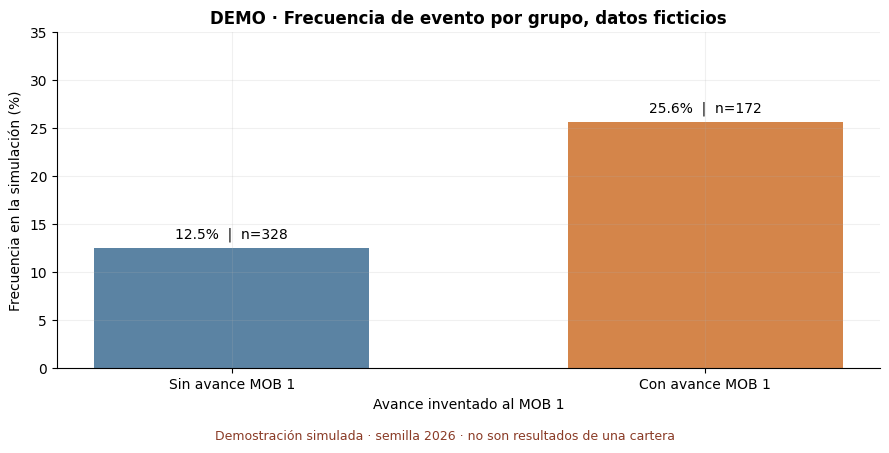

In [3]:
rng_demo = np.random.default_rng(2026)
N_DEMO = 500
avance_demo = rng_demo.binomial(1, .35, N_DEMO)
# Probabilidades elegidas por diseño para esta ilustración, no estimadas.
prob_demo = np.where(avance_demo == 1, .23, .08)
evento_demo = rng_demo.binomial(1, prob_demo)
demo = pd.DataFrame({'grupo': np.where(avance_demo == 1, 'Con avance MOB 1', 'Sin avance MOB 1'), 'evento': evento_demo})
summary_demo = demo.groupby('grupo').evento.agg(['size','sum','mean']).reindex(['Sin avance MOB 1','Con avance MOB 1'])
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(summary_demo.index, summary_demo['mean']*100, color=['#5b83a3','#d4854a'], width=.58)
for bar, count in zip(bars, summary_demo['size']):
    ax.annotate(f"{bar.get_height():.1f}%  |  n={count}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', xytext=(0,5), textcoords='offset points', fontsize=10)
ax.set_ylim(0, max(35,summary_demo['mean'].max()*130))
ax.set(title='DEMO · Frecuencia de evento por grupo, datos ficticios', ylabel='Frecuencia en la simulación (%)', xlabel='Avance inventado al MOB 1')
fig.text(.5,.01,'Demostración simulada · semilla 2026 · no son resultados de una cartera',ha='center',fontsize=9,color='#8a3b26')
plt.tight_layout(rect=(0,.04,1,1));plt.show()

## 3 · Plantilla para alerta MOB 1

`plantilla_modelado_mob1.csv` es un **contrato de integración sin filas**, no una fuente adicional de clientes. Debe ser generado a partir de cohortes y eventos reconciliados, con una fila por cuenta y fecha de decisión. `estado_en_riesgo_mob1=1` significa sin evento >30 hasta la decisión; `seguimiento_completo_mob3=1` confirma medición íntegra posterior. `target_ever_gt30_mob2_3` es la etiqueta futura, distinta del indicador EVER completo usado para backtesting. `fecha_disponibilidad_max` es el máximo de disponibilidad de **todos** los predictores incluidos; `fecha_disponibilidad_target` es la fecha en que la etiqueta puede usarse para entrenar. Estas fechas requieren evidencia de origen.

Monto de avance observado cero significa *cero confirmado*; un valor nulo significa información no disponible. Una cuenta solo puede incluir `primer_mob_avance` 1 o un nulo en esta tabla; un avance conocido por primera vez en MOB 2 o 3 sería fuga.

In [4]:
path = BASE/'plantilla_modelado_mob1.csv'
cohortes = pd.read_csv(path)
print(f'Filas de la plantilla de seguimiento MOB 1: {len(cohortes):,}')
if cohortes.empty:
    print('PENDIENTE: cargar tabla autorizada de cuentas elegibles con fuentes y fechas verificadas.')
else:
    display(cohortes.dtypes.to_frame('tipo inferido'))

Filas de la plantilla de seguimiento MOB 1: 0
PENDIENTE: cargar tabla autorizada de cuentas elegibles con fuentes y fechas verificadas.


## 4 · Puertas de aceptación y riesgo temporal

Antes de calcular perfiles o ajustar un modelo: unicidad por `loan_key, merchant_key`, llave de cliente, fechas válidas, etiqueta binaria, seguimiento íntegro, disponibilidad de predictores anterior a la decisión y estado en riesgo. La validación fallará si el dato no cumple; no se sustituyen ausencias por comportamiento sano.

In [5]:
features_num = ['score_buro', 'avance_mob1_cop']
features_cat = ['tipo_cliente', 'estrategia_originacion', 'departamento']
target = 'target_ever_gt30_mob2_3'
model_ready = False
if not cohortes.empty:
    df = cohortes.copy()
    keys = ['loan_key','merchant_key']
    required = keys + ['client_id','fecha_originacion','fecha_decision','fecha_disponibilidad_max',
                        'fecha_disponibilidad_target','estado_en_riesgo_mob1','seguimiento_completo_mob3',target]
    assert not df[required].isna().any().any(), 'Hay campos obligatorios nulos'
    assert not df.duplicated(keys).any(), 'Hay cuentas duplicadas'
    for col in ['fecha_originacion','fecha_decision','fecha_disponibilidad_max','fecha_disponibilidad_target']:
        df[col] = pd.to_datetime(df[col],errors='raise')
    assert (df.fecha_originacion <= df.fecha_decision).all(), 'Decisión anterior a la originación'
    assert (df.fecha_disponibilidad_max <= df.fecha_decision).all(), 'Hay fuga: predictor disponible después de la decisión'
    assert (df.fecha_disponibilidad_target > df.fecha_decision).all(), 'La etiqueta debe estar disponible después de la decisión'
    assert df.estado_en_riesgo_mob1.eq(1).all() and df.seguimiento_completo_mob3.eq(1).all(), 'Se requieren cuentas en riesgo y seguimiento completo'
    assert df[target].isin([0,1]).all(), 'La etiqueta debe ser 0 o 1'
    assert pd.to_numeric(df.avance_mob1_cop,errors='coerce').ge(0).all(), 'El avance debe ser no negativo y observable'
    first = pd.to_numeric(df.primer_mob_avance,errors='coerce')
    assert (first.isna() | first.eq(1)).all(), 'Primer avance fuera de MOB 1: no admisible a esta fecha'
    assert ((df.avance_mob1_cop == 0) == first.isna()).all(), 'Reconciliar monto y primer avance observado'
    model_ready = True
    print('Puertas estructurales superadas:',len(df),'cuentas. Esto no valida la fuente ni las fechas declaradas.')
else:
    print('PENDIENTE: no hay datos para evaluar las puertas de aceptación.')

PENDIENTE: no hay datos para evaluar las puertas de aceptación.


## 5 · AFM mixto y perfiles: fundamentos y límites

El **análisis factorial múltiple (AFM)** permite equilibrar bloques. Para cada bloque $X_g$, se determina su primera inercia $\lambda_{g,1}$ tras el tratamiento apropiado del tipo de variable y se pondera el bloque por $1/\sqrt{\lambda_{g,1}}$ antes del análisis global. Las variables categóricas requieren un tratamiento coherente con correspondencias múltiples, pesos por modalidad y categorías raras. **No se presenta una PCA de variables mixtas como AFM.**

Bloques propuestos: (1) score y cupo conocido en originación; (2) tipo, estrategia y geografía; (3) importe e indicador de avance hasta la fecha de decisión. Evitar doble ponderación involuntaria de avance e importe. Ajustar imputación, categorías y pesos solo en entrenamiento; proyectar cohortes nuevas con la transformación congelada. La etiqueta y el saldo en mora serán **suplementarios**, nunca activos. Elegir dimensiones por inercia y estabilidad; documentar biblioteca y codificación antes de ejecución.

Para perfiles mixtos contrastar K-Prototypes o distancia de Gower con alternativas sencillas. Elegir $K$ por estabilidad en cohortes posteriores, tamaño mínimo, silhouette apropiada y utilidad; 4 o 5 son candidatos, no una conclusión. Los nombres serán descriptivos, por ejemplo `avance en MOB 1`, sin atribuir intenciones ni riesgo no medido. Informar tablas por cohorte y perfil con denominador, EVER >30 (#), saldo y cobertura del notebook 02. La celda posterior muestra una implementación opcional de AFM mixto y K-means sobre factores, pendiente de validación con la población real. No sustituye la evaluación de K-Prototypes ni un estudio formal de estabilidad.

## 6 · Asociación exploratoria: Cramér V y Spearman

Para dos variables categóricas, $V=\sqrt{\chi^2/[n\min(r-1,c-1)]}$. Una prueba de independencia pequeña puede fallar si las frecuencias esperadas son bajas; reportamos el número de celdas con esperado <5 y no afirmamos significancia cuando el supuesto es débil. Spearman mide asociación **monotónica** de rangos, no causalidad ni necesariamente relaciones no monotónicas. Las comparaciones son exploratorias y no corrigen multiplicidad.

In [6]:
if model_ready:
    from scipy.stats import chi2_contingency, spearmanr
    pairs = df[['tipo_cliente','estrategia_originacion']].dropna()
    table = pd.crosstab(pairs.tipo_cliente,pairs.estrategia_originacion)
    if table.shape[0] >= 2 and table.shape[1] >= 2:
        chi,p,dof,expected = chi2_contingency(table,correction=False)
        v = np.sqrt(chi/(table.to_numpy().sum()*min(table.shape[0]-1,table.shape[1]-1)))
        print('Tipo × estrategia: n =',int(table.to_numpy().sum()),'| Cramér V =',round(v,4), '| celdas esperadas <5 =',int((expected<5).sum()))
        if (expected<5).any(): print('No interpretar el valor p asintótico sin un método apropiado para frecuencias pequeñas.')
        else: print('Valor p exploratorio sin ajuste por multiplicidad:',round(p,5))
        display(table)
    numeric = df[features_num].apply(pd.to_numeric,errors='coerce').dropna()
    if len(numeric)>=3 and all(numeric[c].nunique()>1 for c in features_num):
        rho,pval=spearmanr(numeric.score_buro,numeric.avance_mob1_cop)
        print('Spearman score–avance:',round(float(rho),4),'| n =',len(numeric),'| p exploratorio =',round(float(pval),5))
    else: print('Spearman no estimable: pocos pares o una variable constante.')
else:
    print('PENDIENTE: asociaciones sobre datos elegibles.')

PENDIENTE: asociaciones sobre datos elegibles.


### Relación con resultado y comparación por regiones

Para asociación entre estrategia y resultado se reporta $V$ y tamaño de muestra; la prueba de independencia depende de frecuencias esperadas suficientes. Para diferencias de distribución de score por departamento se propone Kruskal–Wallis, no como prueba automática de diferencias de medias: su interpretación requiere considerar forma de las distribuciones y empates. Usamos un mínimo exploratorio de cinco observaciones por grupo; no equivale a potencia estadística. Ninguna prueba ajusta por comparaciones múltiples ni demuestra causalidad. La etiqueta del ejemplo corresponde al resultado posterior a MOB 1, no al EVER completo.

In [7]:
if model_ready:
    from scipy.stats import chi2_contingency, kruskal
    result_table=pd.crosstab(df.estrategia_originacion,df[target])
    if result_table.shape[0]>=2 and result_table.shape[1]>=2:
        chi,pvalue,dof,expected=chi2_contingency(result_table,correction=False)
        v=np.sqrt(chi/(result_table.to_numpy().sum()*min(result_table.shape[0]-1,result_table.shape[1]-1)))
        print('Estrategia × resultado posterior: n=',int(result_table.to_numpy().sum()),'| V=',round(v,4),'| celdas esperadas <5:',int((expected<5).sum()))
        if (expected<5).any(): print('Valor p asintótico no interpretable sin método para frecuencias pequeñas.')
        else: print('p exploratorio sin ajuste:',round(pvalue,5))
    region=df[['departamento','score_buro']].copy();region['score_buro']=pd.to_numeric(region.score_buro,errors='coerce');region=region.dropna()
    samples=[g.score_buro.to_numpy() for _,g in region.groupby('departamento') if len(g)>=5]
    if len(samples)>=2 and len(np.unique(np.concatenate(samples)))>1:
        h,pvalue=kruskal(*samples); print('Kruskal–Wallis: H=',round(float(h),4),'| p exploratorio=',round(float(pvalue),5),'| regiones con n≥5:',len(samples))
    else: print('Kruskal–Wallis no estimable: faltan grupos o variación.')
else: print('PENDIENTE: pruebas por región y resultado sin datos elegibles.')

PENDIENTE: pruebas por región y resultado sin datos elegibles.


## 7 · División temporal y clientes repetidos

Se reserva el 30 % de fechas de decisión más recientes. Los predictores se ajustan con entrenamiento; se elimina de entrenamiento cualquier cliente presente en evaluación. Solo se conservan etiquetas de entrenamiento que ya estaban disponibles **antes de la primera decisión del test**. Esto no sustituye una validación prospectiva ni garantiza que las fechas declaradas sean veraces.

In [8]:
particion = None
if model_ready:
    dates=np.sort(df.fecha_decision.unique())
    if len(dates)>=3:
        idx=max(1,min(len(dates)-1,int(np.floor(len(dates)*0.70))))
        cutoff=pd.Timestamp(dates[idx]); test=df[df.fecha_decision>=cutoff].copy()
        train=df[(df.fecha_decision<cutoff)&(df.fecha_disponibilidad_target<cutoff)&(~df.client_id.isin(test.client_id))].copy()
        print('Corte temporal:',cutoff.date(),'| entrenamiento:',len(train),'| evaluación:',len(test), '| clientes compartidos:',len(set(train.client_id)&set(test.client_id)))
        if len(train)>=100 and len(test)>=30 and train[target].nunique()==2 and test[target].nunique()==2:
            particion=(train,test)
        else: print('PENDIENTE: tamaño mínimo 100/30 y ambos resultados en cada bloque; umbrales de ejemplo, no potencia garantizada.')
    else: print('PENDIENTE: al menos tres fechas distintas de decisión.')
else:
    print('PENDIENTE: división temporal sin datos.')

PENDIENTE: división temporal sin datos.


## 7.1 · AFM mixto y agrupación opcional sobre factores

Con una partición apta, esta celda utiliza [Prince MFA](https://maxhalford.github.io/prince/mfa/) con bloques numéricos y categóricos separados. Requiere `prince==0.20.2` como dependencia **opcional**, no incluida en el entorno mínimo. La mediana, categorías y ponderaciones se aprenden en entrenamiento y se proyecta solo si la evaluación no contiene categorías inéditas. Una categoría nueva bloquea la proyección para evitar asignarla silenciosamente. La elección de 3 grupos es un **ejemplo de sensibilidad**, no un número óptimo: comparar estabilidad en cohortes, mínimos por grupo y métodos de distancia mixta antes de una decisión.

K-means en coordenadas AFM no es K-Prototypes; es un baseline distinto. La tabla de etiquetas al final muestra solo la frecuencia del **resultado futuro** en grupos con al menos 20 cuentas de test; no entrega la medida $ porque la fecha de saldo no está definida en esta tabla. No usar perfil ni distancia como diagnóstico de fraude.

In [9]:
if particion is None:
    print('PENDIENTE: no se ajusta AFM mixto sin tabla elegible y partición temporal.')
else:
    try:
        import prince
        from sklearn.cluster import KMeans
        from importlib.metadata import version
    except ImportError:
        print('PENDIENTE: instalar la dependencia opcional prince==0.20.2 y volver a ejecutar.')
    else:
        if version('prince') != '0.20.2':
            raise RuntimeError('Validar la versión de prince; el ejemplo se revisó con 0.20.2.')
        train_afm,test_afm = [x.copy() for x in particion]
        groups={'cuantitativas':features_num,'categóricas':features_cat}
        for c in features_num:
            train_afm[c]=pd.to_numeric(train_afm[c],errors='coerce')
            test_afm[c]=pd.to_numeric(test_afm[c],errors='coerce')
            assert train_afm[c].notna().any(), f'{c}: toda la columna de entrenamiento es nula'
            med=train_afm[c].median();train_afm[c]=train_afm[c].fillna(med);test_afm[c]=test_afm[c].fillna(med)
            assert train_afm[c].nunique()>1, f'{c}: variable constante en entrenamiento'
        novedades={}
        for c in features_cat:
            train_afm[c]=train_afm[c].fillna('Sin dato').astype(str)
            test_afm[c]=test_afm[c].fillna('Sin dato').astype(str)
            novedades[c]=sorted(set(test_afm[c])-set(train_afm[c]))
        if any(novedades.values()):
            print('Proyección detenida: categorías de evaluación no vistas en entrenamiento.', novedades)
            print('Definir categorías desconocidas y reentrenar antes de proyectar.')
        else:
            columnas=features_num+features_cat
            afm=prince.MFA(n_components=2,n_iter=5,random_state=42).fit(train_afm[columnas],groups=groups)
            coords_train=afm.row_coordinates(train_afm[columnas]);coords_test=afm.row_coordinates(test_afm[columnas])
            grupos=KMeans(n_clusters=3,random_state=42,n_init=10).fit(coords_train)
            etiqueta=grupos.predict(coords_test)
            evaluacion=pd.DataFrame({'perfil':etiqueta,'resultado':test_afm[target].to_numpy()})
            report=evaluacion.groupby('perfil').resultado.agg(cuentas='size',eventos='sum',tasa='mean')
            report.loc[report.cuentas<20,['eventos','tasa']]=np.nan
            print('AFM mixto: entrenamiento',len(train_afm),'| evaluación',len(test_afm),'| grupos candidatos: 3')
            print('Se suprimen eventos y tasa en grupos de menos de 20 cuentas; revisar umbral de privacidad institucional.')
            display(report)
            print('No se realiza selección automática de K ni se demuestra estabilidad temporal.')

PENDIENTE: no se ajusta AFM mixto sin tabla elegible y partición temporal.


## 8 · Baseline logístico y métricas fuera de tiempo

$P(Y=1\mid X)=\sigma(\beta_0+X^\top\beta)$ y Brier $=N^{-1}\sum_i(p_i-y_i)^2$. La transformación categórica y la imputación se ajustan solo en entrenamiento. AUC y Brier no garantizan calibración ni desempeño por segmento; incluir intervalos agrupados por cliente y evaluación de equidad antes de operar. Los odds ratios no son cambios directos de probabilidad. Las métricas describen aprobados observados y no identifican resultados de rechazados.

In [10]:
if particion is not None:
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
    train,test=particion
    for col in features_num:
        train[col]=pd.to_numeric(train[col],errors='coerce');test[col]=pd.to_numeric(test[col],errors='coerce')
    prep=ColumnTransformer([('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),features_num),
                            ('cat',Pipeline([('fill',SimpleImputer(strategy='constant',fill_value='Sin dato')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),features_cat)])
    model=Pipeline([('prep',prep),('logit',LogisticRegression(max_iter=1000,random_state=42))])
    model.fit(train[features_num+features_cat],train[target]);probs=model.predict_proba(test[features_num+features_cat])[:,1]
    print('AUC:',round(roc_auc_score(test[target],probs),4),'| PR-AUC:',round(average_precision_score(test[target],probs),4),'| Brier:',round(brier_score_loss(test[target],probs),4))
    result=pd.DataFrame({'prob':probs,'resultado':test[target].to_numpy()})
    result['banda']=pd.cut(result.prob,[0,.1,.2,.4,.6,.8,1],include_lowest=True)
    calibration=result.groupby('banda',observed=True).agg(n=('resultado','size'),observada=('resultado','mean'),pronosticada=('prob','mean'))
    display(calibration)
    ax=calibration.plot.scatter(x='pronosticada',y='observada',s=70,c='#216184',title='Calibración fuera de tiempo: bandas fijas')
    ax.plot([0,1],[0,1],ls='--',color='grey');ax.set(xlabel='Probabilidad media estimada',ylabel='Frecuencia observada');plt.tight_layout();plt.show()
else: print('PENDIENTE: sin partición apta no se ajusta ni evalúa un modelo.')

PENDIENTE: sin partición apta no se ajusta ni evalúa un modelo.


## 9 · Anomalías: señal de revisión, no etiqueta

Isolation Forest asigna una puntuación de rareza; no mide probabilidad de fraude. El ejemplo usa el preprocesador ajustado con entrenamiento y un presupuesto ilustrativo del 2 % para exploración. La selección de umbral, precisión top-$k$, tasas por segmento, deriva y capacidad de revisión necesitan etiquetas y validación. LOF requiere tratamiento explícito para datos nuevos; autoencoders y One-Class SVM necesitan selección y evaluación independientes. Ninguno demuestra fraude por sí mismo.

In [11]:
if particion is not None:
    from sklearn.ensemble import IsolationForest
    train,test=particion
    ztrain=model.named_steps['prep'].transform(train[features_num+features_cat]);ztest=model.named_steps['prep'].transform(test[features_num+features_cat])
    forest=IsolationForest(n_estimators=200,contamination=0.02,random_state=42).fit(ztrain)
    selected=forest.predict(ztest)==-1
    print('Alertas exploratorias:',int(selected.sum()),'de',len(test),'| umbral entrenado con contaminación supuesta 2 %')
    print('No interpretar alertas como fraude ni inferir precisión sin revisión/etiquetas.')
else: print('PENDIENTE: sin partición apta no se ajusta detector.')

PENDIENTE: sin partición apta no se ajusta detector.


## 10 · Supervivencia y cierre

Tiempo $T$ al primer DPD >30; censura $C$; observar $\tilde T=\min(T,C)$. Kaplan–Meier estima $\hat S(t)=\prod_{u\le t}(1-d_u/n_u)$, con conjuntos en riesgo y censura correctamente definidos. Para estudiar avances en Cox deben entrar como covariable **dependiente del tiempo**: clasificar retrospectivamente “hizo avance en MOB 1–3” puede producir sesgo de tiempo inmortal. Con solo tres cortes habrá poca resolución; una cuenta que sale por cancelación puede requerir tratamiento de riesgo competitivo. No se implementa KM/Cox sin fecha del evento, censura y validación de supuestos.

**Siguientes pasos:** confirmar definición de >30 y MOB, construir tablas completas con fechas, reservar test temporal, ejecutar controles de calidad y revisar privacidad y tamaños mínimos antes de publicar segmentos. Los gráficos de resultados aparecen cuando hay observaciones aptas; la figura inicial es solamente conceptual.